In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "oecd_vc_annual_2019_2025.csv"
)

df = pd.read_csv(DATA_PATH)

df.head()

,source_provider,source_dataset_id,country_code,country,stage_code,stage,year,vc_investment_usd_millions,observation_status_code,observation_status,unit_code,unit,unit_multiplier_code,unit_multiplier,currency_code,currency
0,OECD,OECD.SDD.TPS:DSD_VC@DF_VC_INV(1.0),AUS,Australia,LATER,Later stage venture,2019,342.02,A,Normal value,USD_EXC,"US dollars, exchange rate converted",6,Millions,USD,US dollar
1,OECD,OECD.SDD.TPS:DSD_VC@DF_VC_INV(1.0),AUS,Australia,SEED,Seed,2019,44.49,A,Normal value,USD_EXC,"US dollars, exchange rate converted",6,Millions,USD,US dollar
2,OECD,OECD.SDD.TPS:DSD_VC@DF_VC_INV(1.0),AUS,Australia,START,Start-up and other early stage,2019,100.80,A,Normal value,USD_EXC,"US dollars, exchange rate converted",6,Millions,USD,US dollar
3,OECD,OECD.SDD.TPS:DSD_VC@DF_VC_INV(1.0),AUS,Australia,_T,Total,2019,487.31,A,Normal value,USD_EXC,"US dollars, exchange rate converted",6,Millions,USD,US dollar
4,OECD,OECD.SDD.TPS:DSD_VC@DF_VC_INV(1.0),AUT,Austria,LATER,Later stage venture,2019,33.96,A,Normal value,USD_EXC,"US dollars, exchange rate converted",6,Millions,USD,US dollar


In [2]:
total_vc = df[df["stage_code"] == "_T"].copy()

stage_vc = df[df["stage_code"].isin(["SEED", "START", "LATER"])].copy()

In [3]:
print(f"Rows: {len(df):,}")
print(f"Countries: {df['country_code'].nunique()}")
print(f"Years: {df['year'].min()}–{df['year'].max()}")

df.groupby("stage")["vc_investment_usd_millions"].agg(
    ["count", "sum", "mean", "median"]
)

Rows: 895
Countries: 37
Years: 2019–2025


,count,sum,mean,median
stage,,,,
Later stage venture,217,"768,081.25","3,539.54",96.30
Seed,217,"143,143.97",659.65,21.19
Start-up and other early stage,217,"518,512.98","2,389.46",105.89
Total,244,"1,468,047.60","6,016.59",247.21


In [4]:
annual_vc = (
    total_vc
    .groupby("year", as_index=False)
    ["vc_investment_usd_millions"]
    .sum()
)

annual_vc

,year,vc_investment_usd_millions
0,2019,"148,307.17"
1,2020,"162,613.24"
2,2021,"336,580.72"
3,2022,"238,395.00"
4,2023,"164,392.27"
5,2024,"196,107.14"
6,2025,"221,652.05"


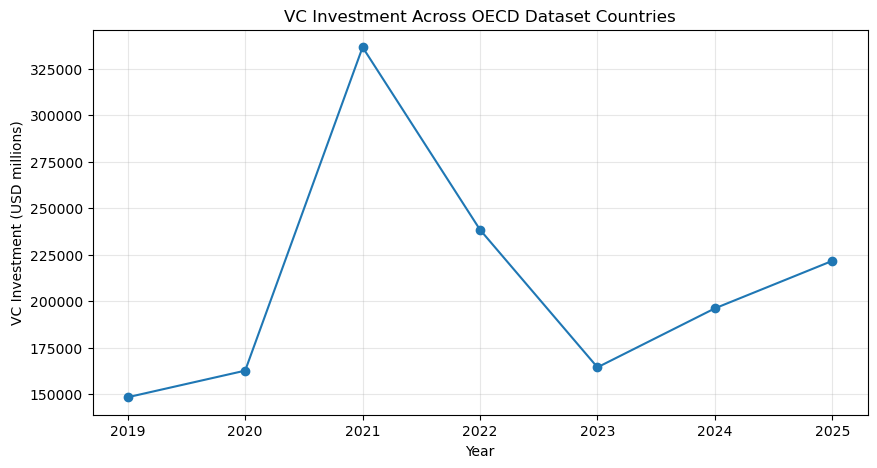

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    annual_vc["year"],
    annual_vc["vc_investment_usd_millions"],
    marker="o"
)

ax.set_title("VC Investment Across OECD Dataset Countries")
ax.set_xlabel("Year")
ax.set_ylabel("VC Investment (USD millions)")
ax.grid(alpha=0.3)

plt.show()

In [6]:
country_totals = (
    total_vc
    .groupby(["country_code", "country"], as_index=False)
    ["vc_investment_usd_millions"]
    .sum()
    .sort_values(
        "vc_investment_usd_millions",
        ascending=False
    )
)

country_totals.head(15)

,country_code,country,vc_investment_usd_millions
35,USA,United States,"1,184,907.20"
18,ISR,Israel,"82,608.29"
4,CAN,Canada,"37,088.49"
13,GBR,United Kingdom,"33,842.65"
21,KOR,Korea,"21,450.03"
7,DEU,Germany,"21,328.57"
12,FRA,France,"17,615.94"
20,JPN,Japan,"14,299.59"
25,NLD,Netherlands,"8,072.47"
9,ESP,Spain,"7,627.17"


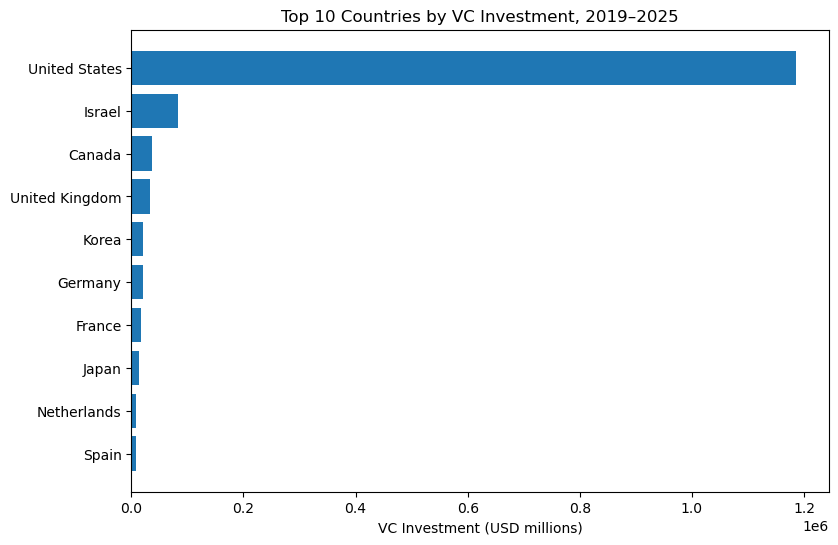

In [7]:
top_10 = country_totals.head(10).sort_values(
    "vc_investment_usd_millions"
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_10["country"],
    top_10["vc_investment_usd_millions"]
)

ax.set_title("Top 10 Countries by VC Investment, 2019–2025")
ax.set_xlabel("VC Investment (USD millions)")

plt.show()

In [8]:
annual_stage = (
    stage_vc
    .groupby(["year", "stage"], as_index=False)
    ["vc_investment_usd_millions"]
    .sum()
)

annual_stage_pivot = annual_stage.pivot(
    index="year",
    columns="stage",
    values="vc_investment_usd_millions"
)

annual_stage_pivot

stage,Later stage venture,Seed,Start-up and other early stage
year,,,
2019,"73,246.02","11,862.64","57,298.15"
2020,"85,616.41","13,875.94","58,272.71"
2021,"193,902.92","22,446.94","112,221.24"
2022,"114,504.41","28,791.33","88,713.34"
2023,"86,742.88","19,976.78","52,882.13"
2024,"100,869.00","21,629.58","68,262.00"
2025,"113,199.61","24,560.76","80,863.42"


In [9]:
stage_share = annual_stage_pivot.div(
    annual_stage_pivot.sum(axis=1),
    axis=0
)

stage_share

stage,Later stage venture,Seed,Start-up and other early stage
year,,,
2019,0.51,0.08,0.40
2020,0.54,0.09,0.37
2021,0.59,0.07,0.34
2022,0.49,0.12,0.38
2023,0.54,0.13,0.33
2024,0.53,0.11,0.36
2025,0.52,0.11,0.37


In [10]:
def classify_period(year):
    if year <= 2021:
        return "Pre-GPT"
    elif year == 2022:
        return "Transition"
    else:
        return "Post-GPT"


total_vc["market_period"] = total_vc["year"].apply(
    classify_period
)

In [11]:
period_summary = (
    total_vc[
        total_vc["market_period"] != "Transition"
    ]
    .groupby("market_period")
    ["vc_investment_usd_millions"]
    .agg(["sum", "mean", "median"])
)

period_summary

,sum,mean,median
market_period,,,
Post-GPT,"582,151.47","5,707.37",270.16
Pre-GPT,"647,501.14","6,051.41",242.75


In [12]:
def top_n_share(group, n=5):
    values = group["vc_investment_usd_millions"]

    if values.sum() == 0:
        return 0

    return (
        values.nlargest(n).sum()
        / values.sum()
    )


top5_share = (
    total_vc
    .groupby("year")
    .apply(top_n_share, include_groups=False)
    .reset_index(name="top5_funding_share")
)

top5_share["top5_funding_share_pct"] = (
    top5_share["top5_funding_share"] * 100
)

top5_share

,year,top5_funding_share,top5_funding_share_pct
0,2019,0.92,91.82
1,2020,0.93,92.79
2,2021,0.94,93.79
3,2022,0.93,92.83
4,2023,0.92,91.83
5,2024,0.92,91.83
6,2025,0.94,93.97
